# Homework 2: Immersed Boundary Methods

In [95]:
import numpy as np
import scipy.linalg as la

import scipy.sparse as sp
import scipy.sparse.linalg as spla

import matplotlib as mpl
import matplotlib.pyplot as plt

import seaborn as sns
import seaborn.objects as so

PI = np.pi

# This setting makes it prints numerical outputs as, e.g. 3.14 and not np.float64(3.14)
# See https://numpy.org/doc/stable/reference/generated/numpy.set_printoptions.html
np.set_printoptions(legacy='1.25')

## Problem 1: Poisson Equation

In [96]:
# Make x, y grid
# assumes square domain
def square_grid(N, borders):
    x_start , x_end, y_start , y_end = borders
    Lx = x_end - x_start
    # Ly = y_end - y_start
    H = Lx/(N - 1)   # Number of cells is gridpoints - 1

    # # GRIDS - arrays of actual x and y values
    # unknowns are ordered k = i + j* N (x varies fastest )
    x_grid = x_start + H * np.arange(N)
    y_grid = y_start + H * np.arange(N)

    return (x_grid, y_grid, H)

# Poisson solver
# Assumes Dirichlet conditions on all boundaries of a square domain
# Inputs:
# N = number of grid points along each axis (assumes Nx=Ny)
# f_rhs = right hand side function
# borders: domain as [x_min,x_max,y_min,y_max]
# bconditions: boundary conditions as two functions, bc_lr for the left and right boundaries and bc_ul for upper and lower boundaries

def make_laplace(N, f_rhs, borders, bconditions):

    x_grid, y_grid, H = square_grid(N, borders)

    bc_lr = bconditions[0]
    # bc_ul = bconditions[1]

    # Build the Laplacian

    rows, cols, vals = [], [], []
    arr_rhs = np.zeros(N*N)

    for i in range(N):
        for j in range(N):
            k = i + j * N      # Flattened index
            if i % N == 0 or i % N == N-1:
                arr_rhs[k] =  bc_lr(x_grid[i],y_grid[j])  # Dirichlet BC on left and right vertical axes
                rows.append(k); cols.append(k); vals.append(1)
            elif j == 0 or j == N-1:
                arr_rhs[k] = 0 # bc_ul(x_grid[i],y_grid[j])      # Dirichlet BC on upper and lower horizontal axes
                rows.append(k); cols.append(k); vals.append(1)
            else:
                rows.append(k); cols.append(k); vals.append(-4)    # Basic 5 point Laplacian
                rows.append(k); cols.append(k+1); vals.append(1)
                rows.append(k); cols.append(k-1); vals.append(1)
                rows.append(k); cols.append(k+N); vals.append(1)
                rows.append(k); cols.append(k-N); vals.append(1)
                arr_rhs[k] = H*H*f_rhs(x_grid[i],y_grid[j])       # RHS function with H^2

    A_full = sp.coo_matrix((vals,(rows,cols)), shape=(N*N,N*N)).tocsr()

    return (A_full, arr_rhs)


def sol_poisson(N, f_rhs, borders, bconditions):

    A_full, arr_rhs = make_laplace(N, f_rhs, borders, bconditions)

    return spla.spsolve(A_full, arr_rhs)


In [97]:
# Apply solver to this problem

# Right hand side function to feed into poisson solver

def f_rhs(x,y):
    return -8 * np.cos(2*x) * np.sin(2*y)

# Manufactured solution
def f_manu(x,y):
    return np.cos(2*x) * np.sin(2*y)

# Domain for this problem
domain2pi = [0, 2*PI, 0, 2*PI]

# Boundary conditions for this problem
def bc_lr(x,y):
    return np.sin(2*y)

def zero_func(x,y):
    return 0

bconditions = [bc_lr, zero_func]

# GRIDIFY and also flatten
# This assumes the square domain [0,2pi] on each side
# So top part is copy paste from def sol_poisson above

def gridify(func, N, borders):
    x_grid, y_grid, H = square_grid(N, borders)

    flat_func = np.zeros(N*N)

    for i in range(N):
        for j in range(N):
            k = i + j * N
            flat_func[k] = func(x_grid[i], y_grid[j])

    return flat_func


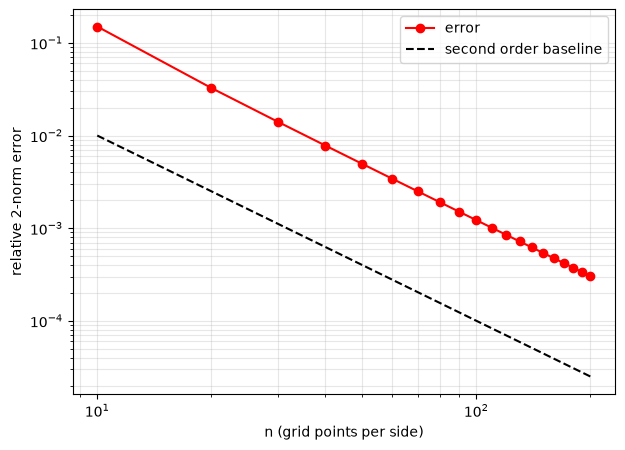

In [98]:
# Plot error for basic problem

num_gpts = np.arange(10, 201, 10)

sols = [sol_poisson(n, f_rhs, domain2pi, bconditions) for n in num_gpts]
exacts = [gridify(f_manu, n, domain2pi) for n in num_gpts]
errors = [la.norm(sols[idx] - exacts[idx]) / la.norm(exacts[idx]) for idx in range(len(num_gpts))]

fig1, ax1 = plt.subplots(figsize=(7, 5))
ax1.loglog(num_gpts, errors, "o-", color="red", label="error")

ax1.loglog(num_gpts, 1/(num_gpts*num_gpts), "--", color="black", label="second order baseline") # Second order reference

ax1.set_xlabel("n (grid points per side)")
ax1.set_ylabel("relative 2-norm error")
ax1.grid(True, which="both", alpha=0.3)
ax1.legend()
plt.show()

fig1.savefig("error_plot1.pdf", bbox_inches="tight")

## Problem 2: Immersed Boundary

In [99]:
# Set up immersed boundary grid and draw a picture
# Make it a function so delta theta connects to delta x

def circle_grid(N, borders):
    # measure the perimeter with a fine sampling of the circle
    th = np.linspace (0 , 2*PI , 10001)
    perimeter = np.sum ( np.hypot ( np.diff ( np.cos ( th )) , np.diff ( np.sin ( th ))))
    # Just take delta theta ~ H. See fun Taylor series argument in scratch paper.
    ds_target = square_grid(N,borders)[2]
    # average spacing of IB points
    Nib = int ( np.ceil ( perimeter / ds_target ))
    theta = 2*PI* np . arange ( Nib ) / Nib
    Xib = PI + np.cos ( theta )
    Yib = PI + np.sin ( theta )

    return (Nib, Xib, Yib)

# Two-dimensional Gaussian regularized delta function

def delta_a ( rx, ry, N, borders) :
    a = 1.2*square_grid(N, borders)[2]
    return np.exp ( -( rx**2 + ry**2) /(2*a**2) ) /(2*PI *a**2)

# Spreading operator "S"
# Check: is this in error?

def spread (q, N, borders):
    Nib, Xib, Yib = circle_grid(N, borders)
    # Original rectangular grid
    X, Y, H = square_grid(N, borders)
    # charges at the IB points
    F = np.zeros (( N , N ) )
    for k in range ( Nib ) :
        F += q [ k ]* delta_a ( X - Xib [k], Y - Yib [k ], N, borders)
    return F

# Interpolation operator "J"
# Check: is this in error??

def interp (U, N, borders):
    Nib, Xib, Yib = circle_grid(N, borders)
    # Original rectangular grid
    X, Y, H = square_grid(N, borders)
    # values at the IB points
    out = np.zeros ( Nib )
    for k in range ( Nib ) :
        out [ k ] = np . sum ( U * delta_a (X - Xib [k], Y - Yib [k ], N, borders) )* H**2
    return out

# Alternative spreading and interpolation operators
def make_ib_operators(N, borders):
    x_grid, y_grid, H = square_grid(N, borders)
    Nib, Xib, Yib = circle_grid(N, borders)
    X, Y = np.meshgrid(x_grid, y_grid)      # X[j,i] = x_grid[i], so ravel() gives k = i + j*N
    Xf, Yf = X.ravel(), Y.ravel()
    D = delta_a(Xf[:, None] - Xib, Yf[:, None] - Yib, N, borders)   # (N*N, Nib)
    on_bdry = (Xf == x_grid[0]) | (Xf == x_grid[-1]) | (Yf == y_grid[0]) | (Yf == y_grid[-1])
    S = D.copy(); S[on_bdry, :] = 0         # spreading: no forcing in Dirichlet rows
    J = H**2 * D.T                          # interpolation
    return S, J, Xib, Yib

def make_saddle(N, f_rhs, ib_rhs, borders, bconditions):
    L, rhs_u = make_laplace(N, f_rhs, borders, bconditions)
    S, J, Xib, Yib = make_ib_operators(N, borders)
    H = square_grid(N, borders)[2]
    n_u, n_q = N*N, len(Xib)

    def apply_saddle(v):
        u, q = v[:n_u], v[n_u:]
        top = L @ u - H**2 * (S @ q)        # H^2 to match the H^2-scaled Laplacian rows
        bottom = J @ u
        return np.concatenate([top, bottom])

    A = spla.LinearOperator((n_u + n_q, n_u + n_q), matvec=apply_saddle)
    b = np.concatenate([rhs_u, ib_rhs(Xib, Yib)])
    return A, b, n_u

def full_sol(N, f_rhs, ib_rhs, borders, bconditions):
    A, b, n_u = make_saddle(N, f_rhs, ib_rhs, borders, bconditions)
    H = square_grid(N, borders)[2]
    tol = max(1e-12, 0.001*H*H)
    sol, info = spla.gmres(A, b, rtol=tol, restart=len(b), maxiter=1)
    u, q = sol[:n_u], sol[n_u:]

    return u, q, info


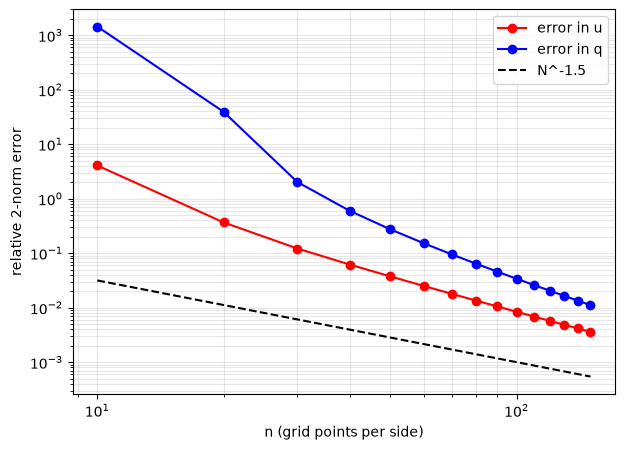

In [100]:
# Plot error for immersed boundary problem

num_gpts2 = np.arange(10, 151, 10)

sols_u = [full_sol(n, f_rhs, f_manu, domain2pi, bconditions)[0] for n in num_gpts2]
exacts_u = [gridify(f_manu, n, domain2pi) for n in num_gpts2]
errors_u = [la.norm(sols_u[idx] - exacts_u[idx]) / la.norm(exacts_u[idx]) for idx in range(len(num_gpts2))]

# Plot exact solution on immersed boundary
# Like gridify but for the ib.
def put_on_circle(func, N, borders):
    Nib, Xib, Yib = circle_grid(N, borders)
    circle_func = np.zeros(Nib)

    for k in range(Nib):
        circle_func[k] = func(Xib[k], Yib[k])

    return circle_func

sols_q = [full_sol(n, f_rhs, f_manu, domain2pi, bconditions)[1] for n in num_gpts2]
# exacts_q = [put_on_circle(f_manu, n, domain2pi) for n in num_gpts2] # NO THIS IS WRONG IT USES F NOT Q
# For this problem, the correct charge is q=0 everywhere!
errors_q = [la.norm(sols_q[idx]) for idx in range(len(num_gpts2))]

fig2, ax2 = plt.subplots(figsize=(7, 5))
ax2.loglog(num_gpts2, errors_u, "o-", color="red", label="error in u")
ax2.loglog(num_gpts2, errors_q, "o-", color="blue", label="error in q")

ax2.loglog(num_gpts2, 1/(num_gpts2**1.5), "--", color="black", label="N^-1.5") # Second order reference

ax2.set_xlabel("n (grid points per side)")
ax2.set_ylabel("relative 2-norm error")
ax2.grid(True, which="both", alpha=0.3)
ax2.legend()
plt.show()

fig2.savefig("error_plot2.pdf", bbox_inches="tight")

# info_list = [full_sol(n, f_rhs, f_manu, domain2pi, bconditions)[2] for n in num_gpts2]

# print(info_list)

## Problem 3: An Almost Minimal Surface

Same as problem 2, but with RHS f = 0 and all boundaries u = 0

max |J u - g| on the circle: 5.682750084945454e-07


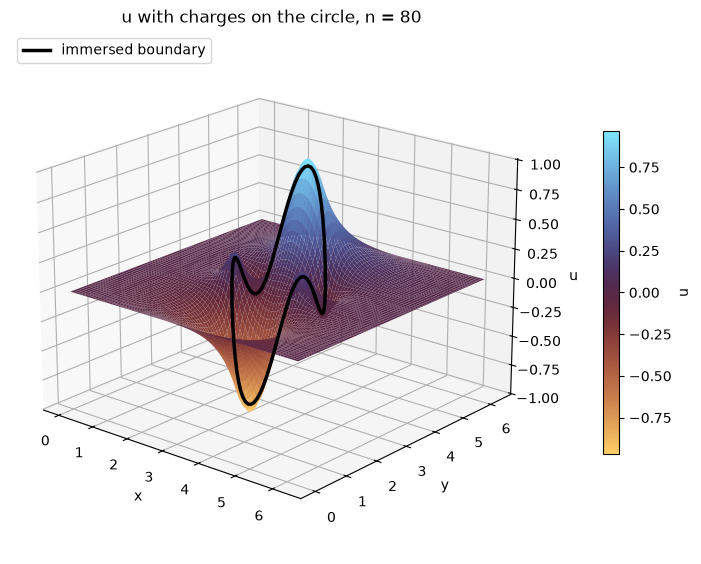

In [115]:
new_bc = [zero_func, zero_func]
new_rhs = zero_func

# Thank you Claude for the plotting

def plot_solution_3d(u, N, borders, g_ib=None, title="Solution u"):
    x_grid, y_grid, H = square_grid(N, borders)
    X, Y = np.meshgrid(x_grid, y_grid)       # X[j,i] = x_grid[i]
    U = u.reshape(N, N)                      # U[j,i] = u at k = i + j*N, same layout as X, Y

    Nib, Xib, Yib = circle_grid(N, borders)
    S, J, _, _ = make_ib_operators(N, borders)
    Zib = J @ u                              # u interpolated onto the circle (should match g_ib)
    # repeat the first point so the circle closes
    Xc, Yc, Zc = (np.append(a, a[0]) for a in (Xib, Yib, Zib))

    umax = np.abs(U).max()
    fig = plt.figure(figsize=(9, 7))
    ax = fig.add_subplot(projection="3d", computed_zorder=False)
    surf = ax.plot_surface(X, Y, U, cmap="managua", vmin=-umax, vmax=umax,
                           rstride=1, cstride=1, linewidth=0, antialiased=True, zorder=1)
    ax.plot(Xc, Yc, Zc, color="black", linewidth=2.5, zorder=10, label="immersed boundary")

    ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("u")
    ax.set_title(title)
    ax.view_init(elev=20, azim=-50)
    fig.colorbar(surf, ax=ax, shrink=0.6, pad=0.1, label="u")
    ax.legend(loc="upper left")
    if g_ib is not None:
        print("max |J u - g| on the circle:", np.abs(Zib - g_ib(Xib, Yib)).max())
    return fig, ax

n = 80
u, q, info = full_sol(n, new_rhs, f_manu, domain2pi, new_bc)
fig3, ax3 = plot_solution_3d(u, n, domain2pi, g_ib=f_manu, title=f"u with charges on the circle, n = {n}")
plt.show()
fig3.savefig("prob3plot.pdf", bbox_inches="tight")


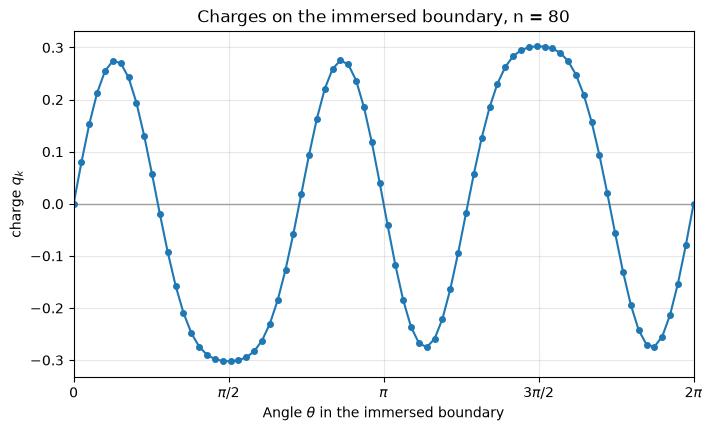

In [108]:
# Plot the charges around the immersed boundary!

def plot_charges(q, N, borders, title="Charges on the immersed boundary"):
    Nib, Xib, Yib = circle_grid(N, borders)
    theta = 2*PI*np.arange(Nib)/Nib          # same parametrization as circle_grid

    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.axhline(0, color="0.6", linewidth=1, zorder=1)
    # repeat the first point at theta = 2*pi so the periodic curve closes
    theta_c, q_c = np.append(theta, 2*PI), np.append(q, q[0])
    ax.plot(theta_c, q_c, "o-", color="tab:blue", markersize=4, linewidth=1.5, zorder=2)

    ax.set_xlim(0, 2*PI)
    ax.set_xticks(np.arange(0, 2*PI + 0.01, PI/2))
    ax.set_xticklabels(["0", r"$\pi/2$", r"$\pi$", r"$3\pi/2$", r"$2\pi$"])
    ax.set_xlabel(r"Angle $\theta$ in the immersed boundary")
    ax.set_ylabel(r"charge $q_k$")
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
    return fig, ax

fig4, ax4 = plot_charges(q, n, domain2pi, title=f"Charges on the immersed boundary, n = {n}")
plt.show()
fig4.savefig("charges_plot.pdf", bbox_inches="tight")

## Sandbox

In [102]:
def foo(x,y):
    x = x + 1
    y += 1
    z = x+y
    return (x,y,z)


